## draft

In [1]:

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.model_selection import GridSearchCV


# 2. DATASET

df = pd.read_csv("houses.csv") #changed the name....dont ask me why

print("First 5 rows:")
print(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical description:")
print(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

First 5 rows:
   surface_m2  nb_pieces  age_annees  distance_centre_km  garage  prix_keuros
0         123          5          22                19.7       1        254.0
1          83          3          24                14.5       0        174.9
2         133          4           8                19.0       1        327.7
3         114          3          21                 2.8       1        275.2
4          41          1          30                17.1       0         56.8

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   surface_m2          150 non-null    int64  
 1   nb_pieces           150 non-null    int64  
 2   age_annees          150 non-null    int64  
 3   distance_centre_km  150 non-null    float64
 4   garage              150 non-null    int64  
 5   prix_keuros         150 non-null    float64
dtypes: flo

#### DATA VISUALIZATION

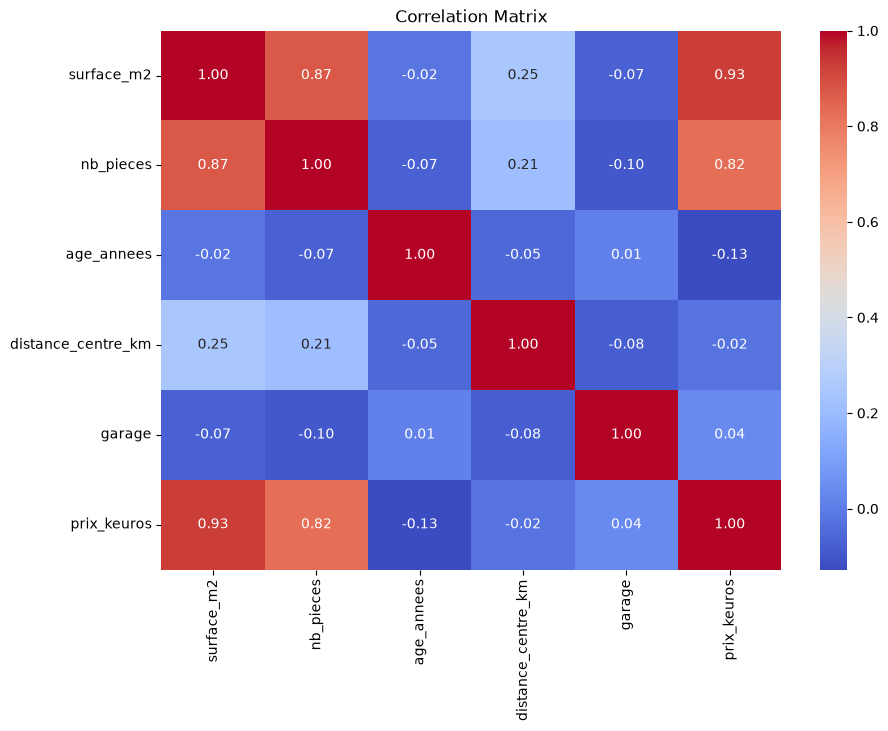

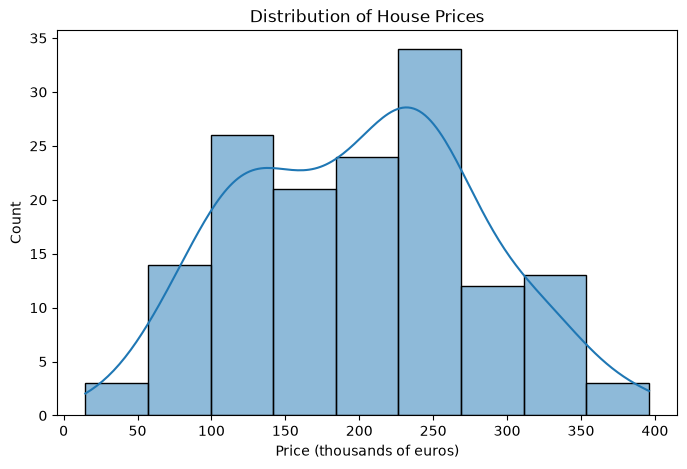

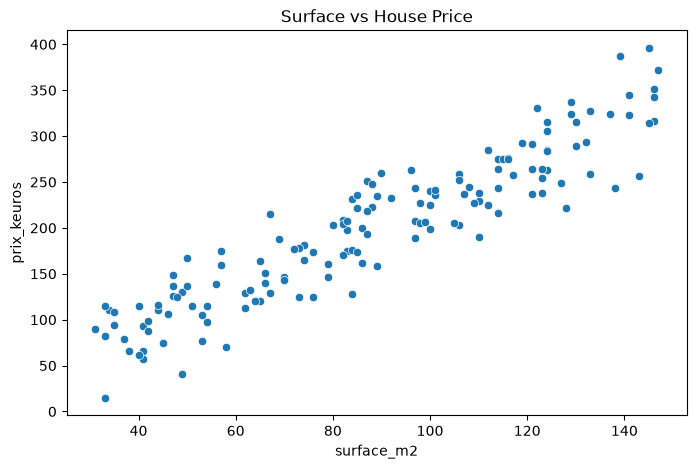

In [2]:

# Correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# Distribution of house prices
plt.figure(figsize=(8, 5))

sns.histplot(
    df["prix_keuros"],
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (thousands of euros)")
plt.show()

# Surface versus price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="surface_m2",
    y="prix_keuros"
)

plt.title("Surface vs House Price")
plt.show()

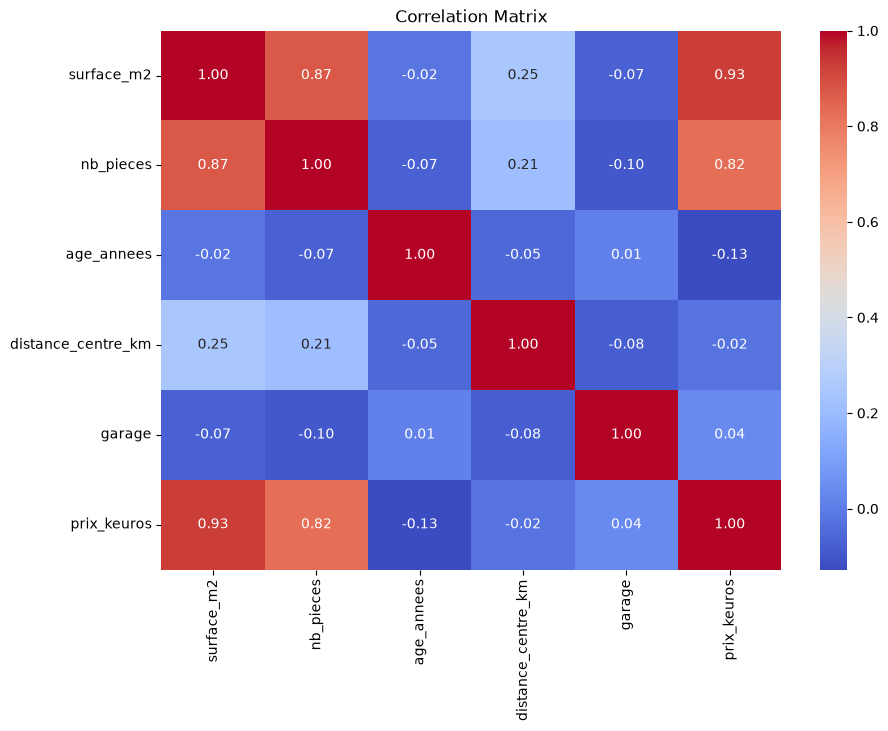

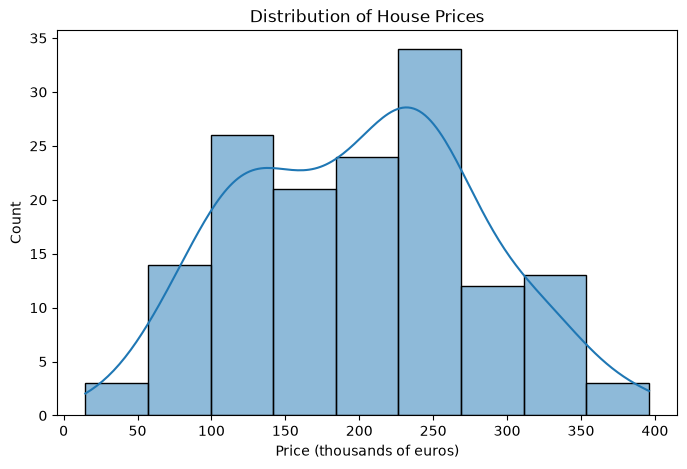

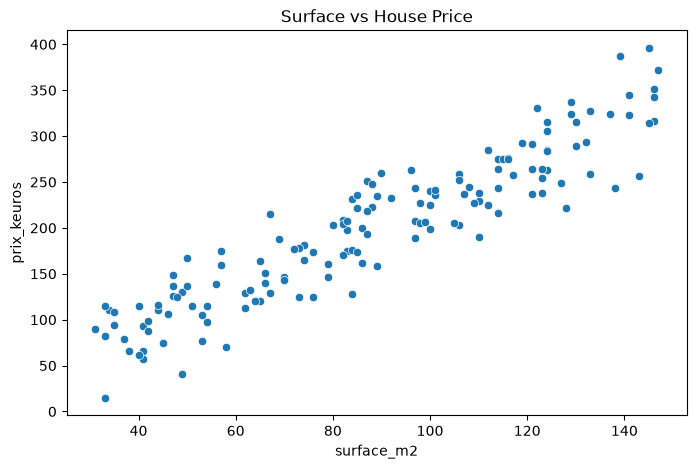

In [2]:

# Correlation matrix
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

# Distribution of house prices
plt.figure(figsize=(8, 5))

sns.histplot(
    df["prix_keuros"],
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Price (thousands of euros)")
plt.show()

# Surface versus price
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="surface_m2",
    y="prix_keuros"
)

plt.title("Surface vs House Price")
plt.show()

#### processing & splitting data

In [3]:
# Separate input variables and target
X = df.drop(columns=["prix_keuros"])
y = df["prix_keuros"]

# Inspect possible outliers using the IQR method
Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["prix_keuros"] < lower_bound) |
    (df["prix_keuros"] > upper_bound)
]

print("\nPossible price outliers:")
print(outliers)#i dont thoink there r outliners

# we inspect outliers instead of automatically deleting them.
# missing values will be handled during model training.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Possible price outliers:
Empty DataFrame
Columns: [surface_m2, nb_pieces, age_annees, distance_centre_km, garage, prix_keuros]
Index: []

Training samples: 120
Testing samples: 30


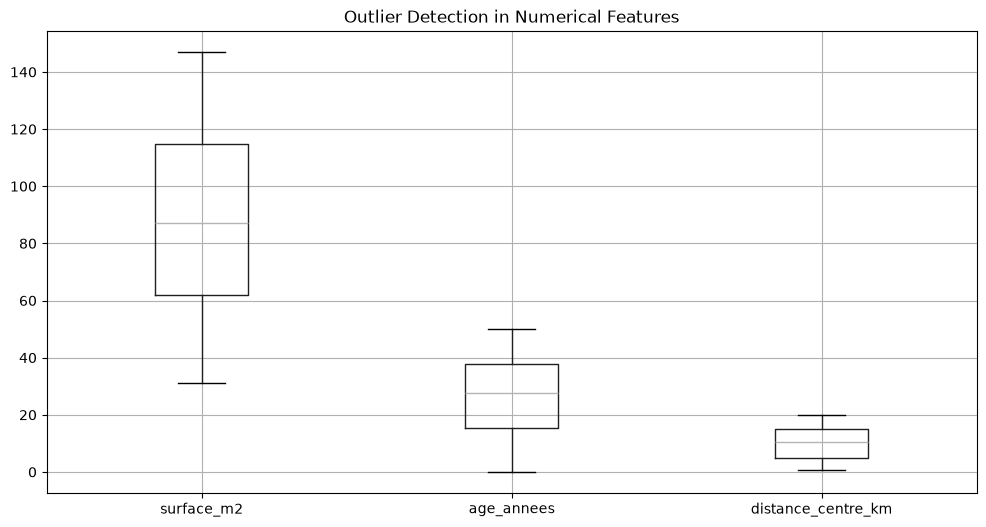

     surface_m2  nb_pieces  age_annees  distance_centre_km  garage  \
135          33          1          22                17.2       1   
28           49          3          48                18.0       0   
4            41          1          30                17.1       0   
122          40          1          32                16.8       0   
17           38          1          15                15.7       1   

     prix_keuros  
135         14.7  
28          41.3  
4           56.8  
122         61.3  
17          66.2  


In [4]:
# Boxplots to inspect possible outliers

plt.figure(figsize=(12, 6))

df[["surface_m2", "age_annees", "distance_centre_km"]].boxplot()

plt.title("Outlier Detection in Numerical Features")
plt.show()

#inspecting ze lower price
print(df.nsmallest(5, "prix_keuros"))

#### model selectin & training

In [5]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42
        ))
    ]),

    "Support Vector Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVR(kernel="rbf"))
    ])
}


# TRAINING AND CROSS-VALIDATION


results = {}

for name, model in models.items():

    # fold cross-validation on training data
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error" ###RMSE=sqrt{(1/n)sum_{i=1}^{n}(y_i- y'_i)^2}

    )

    rmse = -scores.mean()

    results[name] = rmse

    print(f"{name} - CV RMSE: {rmse:.2f}")

# select the model with the lowest CV RMSE
best_model_name = min(results, key=results.get)

best_model = models[best_model_name]

print("\nBest model:", best_model_name)

# train the selected model on the complete training set
best_model.fit(X_train, y_train)


Linear Regression - CV RMSE: 18.72
Random Forest - CV RMSE: 26.08
Support Vector Regression - CV RMSE: 73.95

Best model: Linear Regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['surface_m2','nb_pieces','age_annees','distance_centre_km','garage']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",N

In [6]:
# HYPERPARAMETER TUNING

param_grids = {

    "Linear Regression": {
        "model__fit_intercept": [True, False]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5]
    },

    "Support Vector Regression": {
        "model__C": [1, 10, 100],
        "model__epsilon": [0.1, 0.5],
        "model__gamma": ["scale", "auto"]
    }
}

tuned_models = {}

for name, model in models.items():

    grid = GridSearchCV(
        model,
        param_grids[name],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    tuned_models[name] = grid

    print("\n", name)
    print("Best parameters:", grid.best_params_)
    print("Best CV RMSE:", -grid.best_score_)

# select the best tuned model

best_model_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].best_score_
)

best_model = tuned_models[best_model_name].best_estimator_

print("\n BEST TUNED MODEL")
print("Model:", best_model_name)
print("CV RMSE:", -tuned_models[best_model_name].best_score_)


 Linear Regression
Best parameters: {'model__fit_intercept': True}
Best CV RMSE: 18.720988372694634

 Random Forest
Best parameters: {'model__max_depth': 10, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV RMSE: 25.961876923936785

 Support Vector Regression
Best parameters: {'model__C': 100, 'model__epsilon': 0.1, 'model__gamma': 'auto'}
Best CV RMSE: 27.049760728448653

 BEST TUNED MODEL
Model: Linear Regression
CV RMSE: 18.720988372694634


####  EVALUATION

In [7]:
y_pred = best_model.predict(X_test)

# MAE=(1/n)sum_{i=1}^{n}|y_i-y'_i|

mae = mean_absolute_error(y_test, y_pred)

# MAE=(1/n)sum_{i=1}^{n}[|y_i-y'_i|]^2
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n  model eval")

print(f"MAE  : {mae:.2f} k€")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f} k€")
print(f"R²   : {r2:.4f}")


  model eval
MAE  : 13.56 k€
MSE  : 321.50
RMSE : 17.93 k€
R²   : 0.9439


In [8]:
# FEATURE IMPORTANCE / COEFFICIENTS

final_model = best_model.named_steps["model"]

if isinstance(final_model, LinearRegression):

    coefficients = pd.DataFrame({
        "Feature": X.columns,
        "Coefficient": final_model.coef_
    })

    print(coefficients.sort_values(
        by="Coefficient",
        ascending=False
    ))

    print("Intercept:", final_model.intercept_)

              Feature  Coefficient
0          surface_m2    78.439614
4              garage     7.983209
1           nb_pieces     2.256805
2          age_annees   -11.038313
3  distance_centre_km   -21.351181
Intercept: 198.20833333333334


####  ACTUAL VS PREDICTED PRICES

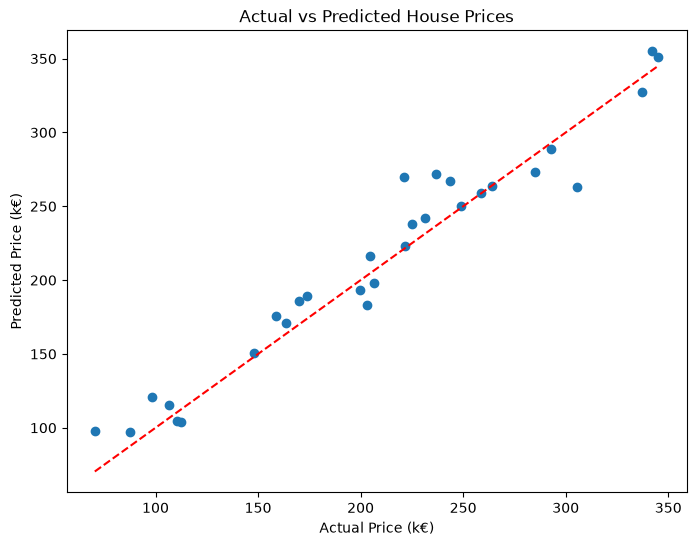

In [9]:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual Price (k€)")
plt.ylabel("Predicted Price (k€)")

plt.title("Actual vs Predicted House Prices")

plt.show()

 ####  PREDICTION ON NEW DATA


In [10]:

new_house = pd.DataFrame([{
    "surface_m2": 100,
    "nb_pieces": 4,
    "age_annees": 10,
    "distance_centre_km": 5.0,
    "garage": 1 #mwntal note...more garages less price?should be tje opposi
}])

predicted_price = best_model.predict(new_house)[0]

print("\n NEW HOUSE PREDICTION ")

print(f"Predicted price: {predicted_price:.2f} k€")

print(f"Predicted price: {predicted_price * 1000:.0f} euros")



 NEW HOUSE PREDICTION 
Predicted price: 271.57 k€
Predicted price: 271567 euros


In [11]:
# SAVE THE TRAINED MODEL

import joblib

joblib.dump(best_model, "house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [12]:
# LOAD THE TRAINED MODEL

loaded_model = joblib.load("house_price_model.pkl")

# Test prediction
prediction = loaded_model.predict(new_house)

print(f"Predicted price: {prediction[0]:.2f} k€")

Predicted price: 271.57 k€
